# Neural Narworks : Exercises

## Exercise 1 :

- Create a neural network to simulate the Sinus function with high precision
- What is the precision of your model at 10e-3 input precision ?

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

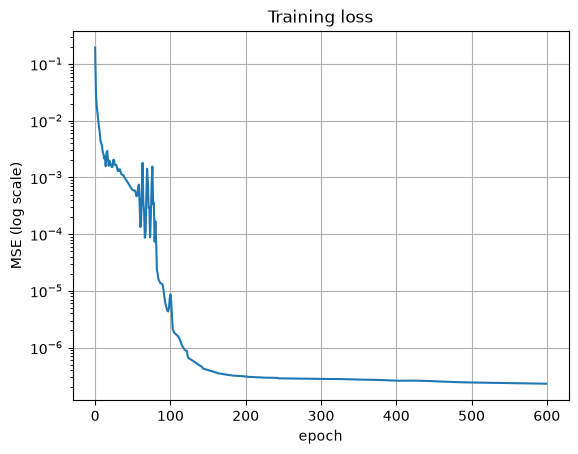

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

keras.utils.set_random_seed(0)

# Training data : one full period of the sinus
x_train = np.linspace(-np.pi, np.pi, 2000).reshape(-1, 1)
y_train = np.sin(x_train)

# Smooth target -> smooth activation (tanh) in the hidden layers, linear output
model_sin = Sequential()
model_sin.add(Input(shape=(1,)))
model_sin.add(Dense(units=32, activation='tanh'))
model_sin.add(Dense(units=32, activation='tanh'))
model_sin.add(Dense(units=1, activation='linear'))
model_sin.compile(loss='mse', optimizer=Adam(learning_rate=0.01))
model_sin.summary()

# Lower the learning rate when the loss stops improving to reach a high precision
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.5, patience=20, min_lr=1e-5)
history_sin = model_sin.fit(x_train, y_train, epochs=600, batch_size=64, callbacks=[reduce_lr], verbose=0)

plt.semilogy(history_sin.history['loss'])
plt.xlabel('epoch'); plt.ylabel('MSE (log scale)'); plt.title('Training loss')
plt.grid()
plt.show()

### Precision at an input precision of 10e-3

`10e-3` literally means 0.01 (it is often written for 10⁻³ = 0.001), so the model is evaluated on both grids over [-π, π].
For a regression, the "precision" is measured with the absolute error |model(x) − sin(x)| (mean and maximum).

step = 0.01 (630 points) : mean abs error = 3.85e-04, max abs error = 2.65e-03


step = 0.001 (6285 points) : mean abs error = 3.80e-04, max abs error = 2.65e-03


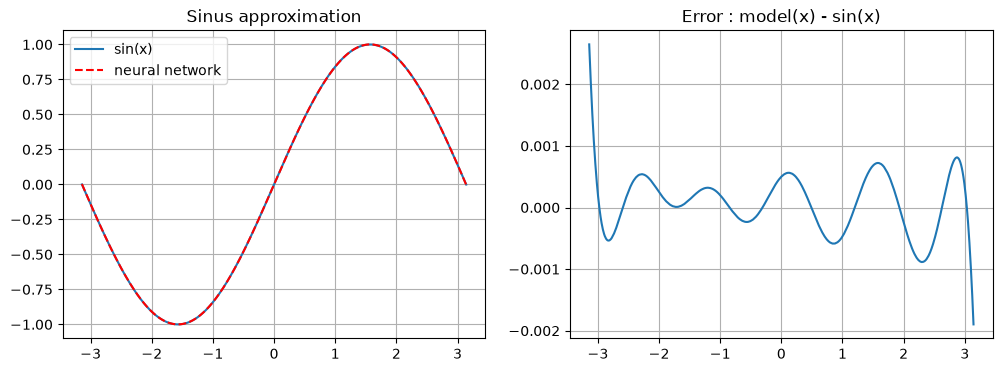

In [ ]:
for step in (10e-3, 1e-3):
    x_test = np.arange(-np.pi, np.pi + step, step).reshape(-1, 1)
    error = np.abs(model_sin.predict(x_test, verbose=0) - np.sin(x_test))
    print(f"step = {step:g} ({len(x_test)} points) : mean abs error = {error.mean():.2e}, max abs error = {error.max():.2e}")

x_test = np.arange(-np.pi, np.pi + 1e-3, 1e-3).reshape(-1, 1)
y_pred = model_sin.predict(x_test, verbose=0)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(x_test, np.sin(x_test), label='sin(x)')
ax[0].plot(x_test, y_pred, 'r--', label='neural network')
ax[0].legend(); ax[0].grid(); ax[0].set_title('Sinus approximation')
ax[1].plot(x_test, y_pred - np.sin(x_test))
ax[1].grid(); ax[1].set_title('Error : model(x) - sin(x)')
plt.show()

## Exercise 2 : 
- Create a neural network to transform a binary value into a decimal value (Use a linear activation and no hidden layers).
- Display the weights of your model and show that it converges to powers of 2 (1, 2, 4 and 8)

In [ ]:
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

keras.utils.set_random_seed(0)

# All the 4-bit binary numbers (most significant bit first) and their decimal value
X_bin = np.array([[int(b) for b in f"{n:04b}"] for n in range(16)], dtype=np.float32)
y_dec = np.arange(16, dtype=np.float32)
print(np.column_stack([X_bin, y_dec]).astype(int))

# No hidden layer, linear activation : y = w1*b3 + w2*b2 + w3*b1 + w4*b0 + bias
model_bin = Sequential()
model_bin.add(Input(shape=(4,)))
model_bin.add(Dense(units=1, activation='linear'))
model_bin.compile(loss='mse', optimizer=Adam(learning_rate=0.05))
model_bin.summary()

history_bin = model_bin.fit(X_bin, y_dec, epochs=1000, verbose=0)
print("final loss :", history_bin.history['loss'][-1])

[[ 0  0  0  0  0]
 [ 0  0  0  1  1]
 [ 0  0  1  0  2]
 [ 0  0  1  1  3]
 [ 0  1  0  0  4]
 [ 0  1  0  1  5]
 [ 0  1  1  0  6]
 [ 0  1  1  1  7]
 [ 1  0  0  0  8]
 [ 1  0  0  1  9]
 [ 1  0  1  0 10]
 [ 1  0  1  1 11]
 [ 1  1  0  0 12]
 [ 1  1  0  1 13]
 [ 1  1  1  0 14]
 [ 1  1  1  1 15]]


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (20.00 B)

 Trainable params: 5 (20.00 B)

 Non-trainable params: 0 (0.00 B)

final loss : 9.733968181535602e-05


weights : [7.9882803 3.9909294 1.9920167 0.9918648]
rounded : [7.988 3.991 1.992 0.992]
bias    : [0.02132634]


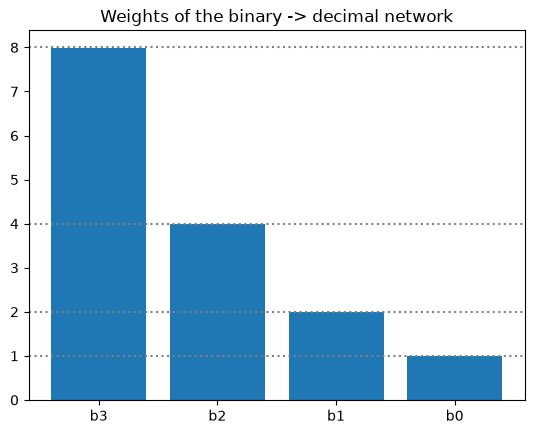

prediction for 1011 : [[10.993488]]


In [ ]:
weights, bias = model_bin.layers[0].get_weights()
print("weights :", weights.ravel())
print("rounded :", np.round(weights.ravel(), 3))
print("bias    :", bias)

# Weights of the bits b3, b2, b1, b0 converge to 8, 4, 2, 1 (powers of 2) and the bias to 0
plt.bar(['b3', 'b2', 'b1', 'b0'], weights.ravel())
plt.axhline(8, ls=':', c='gray'); plt.axhline(4, ls=':', c='gray'); plt.axhline(2, ls=':', c='gray'); plt.axhline(1, ls=':', c='gray')
plt.title('Weights of the binary -> decimal network')
plt.show()

print("prediction for 1011 :", model_bin.predict(np.array([[1, 0, 1, 1]], dtype=np.float32), verbose=0))

## Exercise 3

- Based on this example, create 16 clusters and their associated classes. 
- Repeat it to obtain two datasets, one for training and one for validation.
- Build neural network classifier and train it
- Trace loss and accuracy history. 
- Evaluate it over the validation set and display confusion matrix




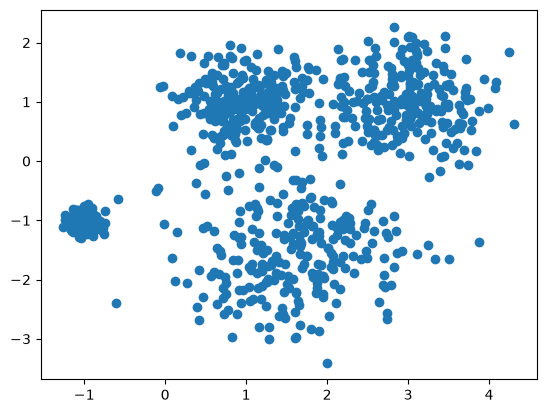

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs

centers = [[1, 1], [-1, -1], [1.5, -1.5], [3, 1]]
X, labels = make_blobs(n_samples=1000, centers=centers, cluster_std=[0.4, 0.1, 0.75, 0.5], random_state=0)

plt.scatter(X[:,0], X[:,1])
plt.show()

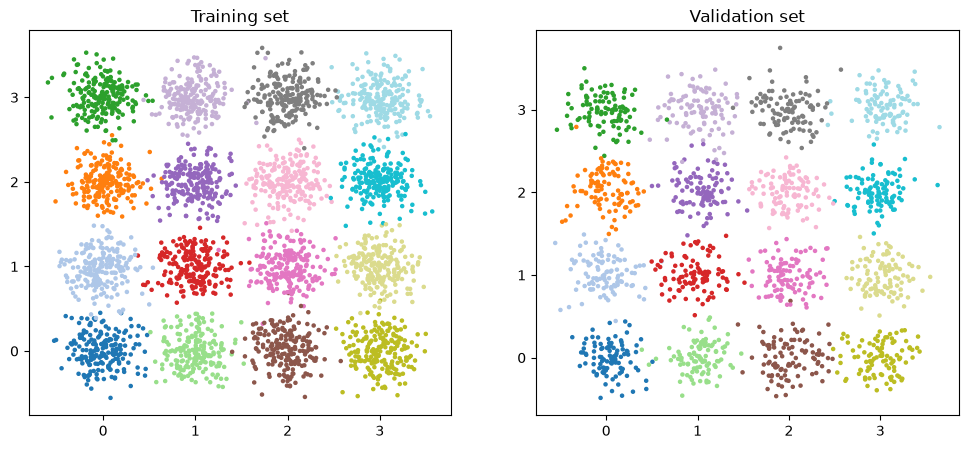

In [ ]:
# 16 clusters on a 4x4 grid, each cluster is a class
centers16 = [[x, y] for x in range(4) for y in range(4)]

# Same centers, two different random draws : one for training, one for validation
X_train3, y_train3 = make_blobs(n_samples=3200, centers=centers16, cluster_std=0.2, random_state=0)
X_val3, y_val3 = make_blobs(n_samples=1600, centers=centers16, cluster_std=0.2, random_state=1)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(X_train3[:, 0], X_train3[:, 1], c=y_train3, cmap='tab20', s=5)
ax[0].set_title('Training set')
ax[1].scatter(X_val3[:, 0], X_val3[:, 1], c=y_val3, cmap='tab20', s=5)
ax[1].set_title('Validation set')
plt.show()

In [ ]:
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

keras.utils.set_random_seed(0)

Y_train3 = to_categorical(y_train3, num_classes=16)
Y_val3 = to_categorical(y_val3, num_classes=16)

model_clusters = Sequential()
model_clusters.add(Input(shape=(2,)))
model_clusters.add(Dense(units=64, activation='relu'))
model_clusters.add(Dense(units=64, activation='relu'))
model_clusters.add(Dense(units=16, activation='softmax'))
model_clusters.compile(loss='categorical_crossentropy', optimizer=Adam(learning_rate=0.01), metrics=['accuracy'])
model_clusters.summary()

history3 = model_clusters.fit(X_train3, Y_train3, validation_data=(X_val3, Y_val3), epochs=100, batch_size=64, verbose=0)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │         1,040 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,392 (21.06 KB)

 Trainable params: 5,392 (21.06 KB)

 Non-trainable params: 0 (0.00 B)

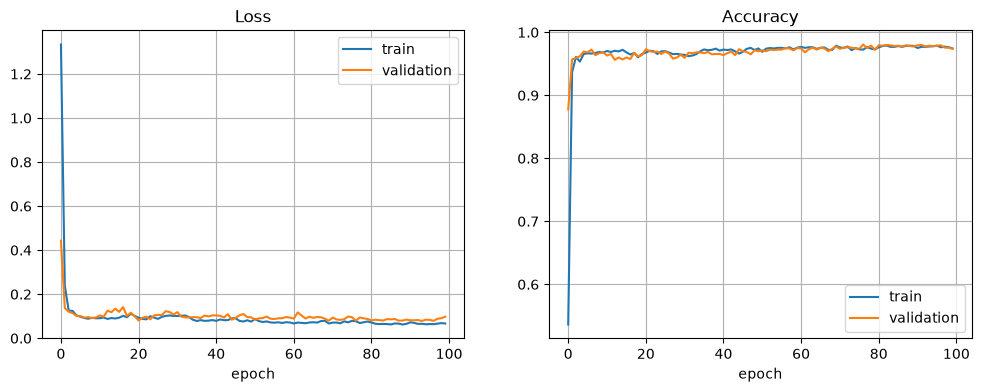

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history3.history['loss'], label='train')
ax[0].plot(history3.history['val_loss'], label='validation')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].grid()
ax[1].plot(history3.history['accuracy'], label='train')
ax[1].plot(history3.history['val_accuracy'], label='validation')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].grid()
plt.show()

Validation loss = 0.0977, validation accuracy = 0.9737


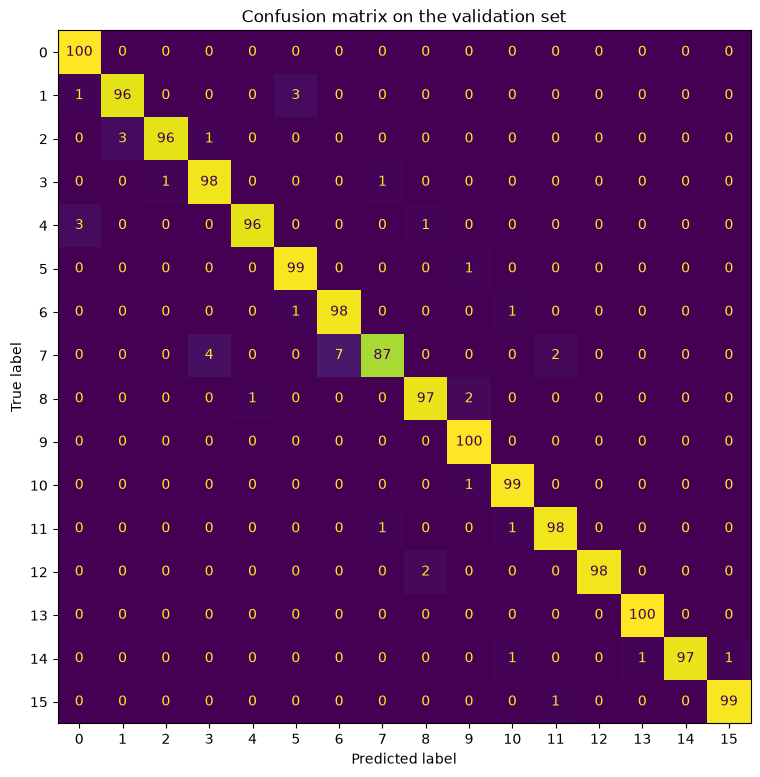

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

val_loss, val_acc = model_clusters.evaluate(X_val3, Y_val3, verbose=0)
print(f"Validation loss = {val_loss:.4f}, validation accuracy = {val_acc:.4f}")

y_pred3 = np.argmax(model_clusters.predict(X_val3, verbose=0), axis=1)
cm = confusion_matrix(y_val3, y_pred3)

fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm).plot(ax=ax, colorbar=False)
ax.set_title('Confusion matrix on the validation set')
plt.show()

# Exercise 4

Create a neural network classifier to classify the given data.

Plot the areas created by your neural network (or a video video if you can). use the code from the previous homework.

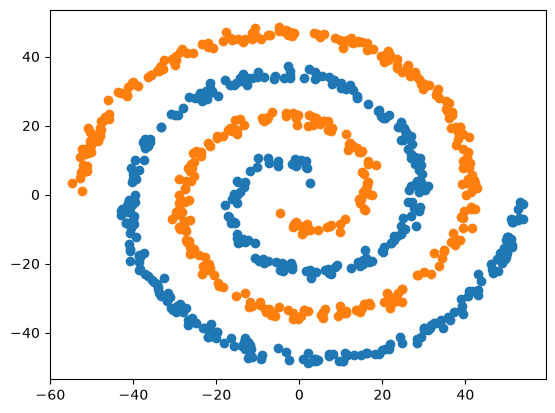

In [ ]:
import numpy as np
from numpy import pi
import matplotlib.pyplot as plt

N = 400
theta = np.sqrt(np.random.rand(N))*4*pi # np.linspace(0,2*pi,100)

r_a = 4*theta + pi
data_a = np.array([np.cos(theta)*r_a, np.sin(theta)*r_a]).T
x_a = data_a + np.random.randn(N,2)

r_b = -4*theta - pi
data_b = np.array([np.cos(theta)*r_b, np.sin(theta)*r_b]).T
x_b = data_b + np.random.randn(N,2)

res_a = np.append(x_a, np.zeros((N,1)), axis=1)
res_b = np.append(x_b, np.ones((N,1)), axis=1)

res = np.append(res_a, res_b, axis=0)
np.random.shuffle(res)

plt.scatter(x_a[:,0],x_a[:,1])
plt.scatter(x_b[:,0],x_b[:,1])
plt.show()

In [ ]:
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

keras.utils.set_random_seed(0)

# res = [x, y, class] (already shuffled)
X_spiral = res[:, :2]
y_spiral = res[:, 2]

# Grid covering the plane, used to draw the areas of each class
xx, yy = np.meshgrid(np.linspace(X_spiral[:, 0].min() - 3, X_spiral[:, 0].max() + 3, 200),
                     np.linspace(X_spiral[:, 1].min() - 3, X_spiral[:, 1].max() + 3, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

model_spiral = Sequential()
model_spiral.add(Input(shape=(2,)))
model_spiral.add(Dense(units=64, activation='relu'))
model_spiral.add(Dense(units=64, activation='relu'))
model_spiral.add(Dense(units=64, activation='relu'))
model_spiral.add(Dense(units=1, activation='sigmoid'))
model_spiral.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=0.003), metrics=['accuracy'])
model_spiral.summary()

# Keep the prediction over the grid during training to build the video afterwards
frames = []
def save_frame(epoch, logs):
    if epoch % 5 == 0:
        frames.append((epoch, model_spiral.predict(grid, batch_size=4096, verbose=0).reshape(xx.shape), logs['accuracy']))

history4 = model_spiral.fit(X_spiral, y_spiral, epochs=400, batch_size=32, verbose=0,
                            callbacks=[keras.callbacks.LambdaCallback(on_epoch_end=save_frame)])
print("final accuracy :", history4.history['accuracy'][-1])

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 64)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,577 (33.50 KB)

 Trainable params: 8,577 (33.50 KB)

 Non-trainable params: 0 (0.00 B)

final accuracy : 1.0


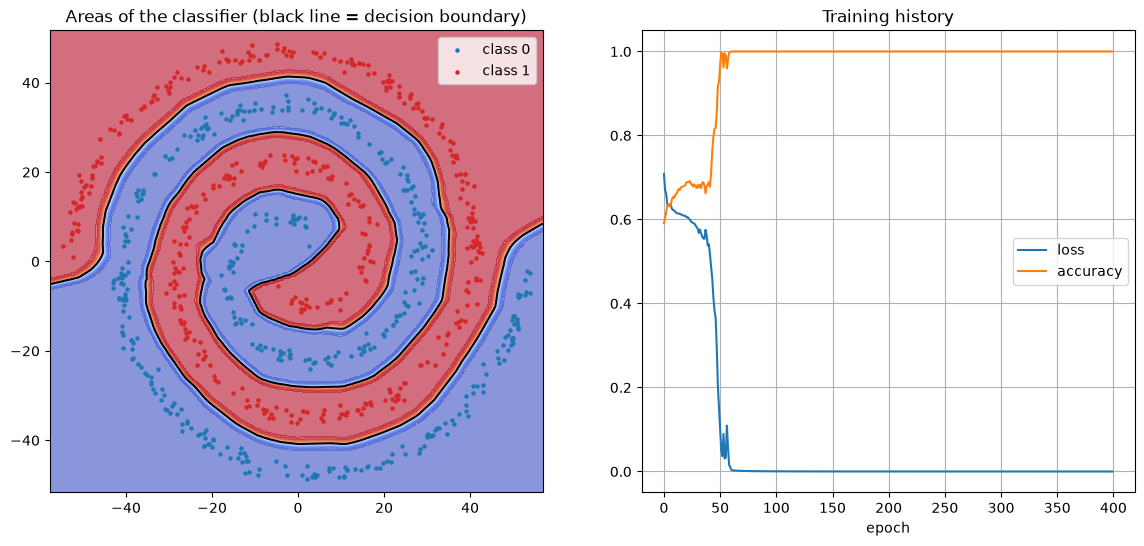

In [ ]:
# Areas created by the neural network
proba = model_spiral.predict(grid, batch_size=4096, verbose=0).reshape(xx.shape)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].contourf(xx, yy, proba, levels=50, cmap='coolwarm', alpha=0.6)
ax[0].contour(xx, yy, proba, levels=[0.5], colors='k')
ax[0].scatter(x_a[:, 0], x_a[:, 1], s=5, c='tab:blue', label='class 0')
ax[0].scatter(x_b[:, 0], x_b[:, 1], s=5, c='tab:red', label='class 1')
ax[0].set_title('Areas of the classifier (black line = decision boundary)')
ax[0].legend()
ax[1].plot(history4.history['loss'], label='loss')
ax[1].plot(history4.history['accuracy'], label='accuracy')
ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].grid()
ax[1].set_title('Training history')
plt.show()

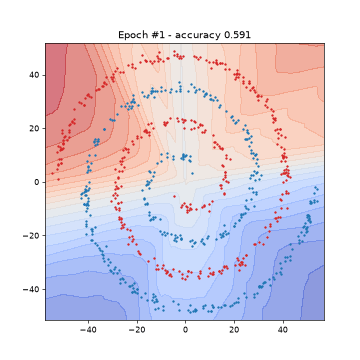

In [ ]:
# Video of the areas during training (same idea as the previous homework, saved as an animated GIF)
import os
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

os.makedirs("img", exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 6))
def draw(i):
    epoch, p, acc = frames[i]
    ax.clear()
    ax.contourf(xx, yy, p, levels=20, cmap='coolwarm', alpha=0.6, vmin=0, vmax=1)
    ax.scatter(x_a[:, 0], x_a[:, 1], s=3, c='tab:blue')
    ax.scatter(x_b[:, 0], x_b[:, 1], s=3, c='tab:red')
    ax.set_title(f"Epoch #{epoch + 1} - accuracy {acc:.3f}")

animation = FuncAnimation(fig, draw, frames=len(frames))
animation.save("img/spiral_training.gif", writer=PillowWriter(fps=10), dpi=60)
plt.close(fig)

Image(filename="img/spiral_training.gif")